In [46]:
import pandas as pd

FILE   = "../data/raw/unison_notas.parquet"
df = pd.read_parquet(FILE).set_index('id')
df.published = pd.to_datetime(df.published)
df.sample(5)

,headline,published,text,author,scraped_at
id,,,,,
15957,Participan universitarios del Campus Navojoa e...,2013-11-19,Estudiantes del campus Navojoa de la Unidad R...,None,2026-11-01T19:47:30.671638+00:00
17400,Presentan EGEL de Ceneval en el Campus Navojoa,2014-08-28,Un total de 48 egresados de diferentes carrer...,None,2026-11-01T20:24:21.669172+00:00
16363,Rinde protesta Adelina Galindo como Jefa del D...,2014-02-04,La académica Adelina Galindo Romero rindió pr...,None,2026-11-01T19:58:07.745176+00:00
13283,Presenta Unison Portafolio de Proyectos Tecnol...,2012-06-21,El Consejo de Vinculación Social de la Univer...,None,2026-11-01T18:38:08.844535+00:00
13300,Conforman 80 alumnos la primera generación de ...,2012-06-26,Alrededor de 80 graduantes de la primera gene...,None,2026-11-01T18:38:34.744243+00:00


# Valores duplicados

Curiosamente se reciclan titulares:

In [42]:
field = 'headline'
df['i'] = df.groupby(field).cumcount()
df[df.duplicated(subset=[field],keep=False)].reset_index().set_index([field,'i']).sort_index()

id   published  \
headline                                           i                      
Alertan sobre deficiencia de Vitamina A en la p... 0  17023  2014-06-16   
                                                   1  17273  2014-07-21   
Analizan la volatilidad económica que se presen... 0  16543  2014-02-28   
                                                   1  16547  2014-02-28   
Contribuye Unison a la investigación y conserva... 0  15156  2013-06-21   
                                                   1  16703  2014-04-22   
Convocan a participar en Especialización en Des... 0  13267  2012-06-19   
                                                   1  14891  2013-05-06   
Empieza Semana de las Artes en el campus Caborca   0  13980  2012-11-13   
                                                   1  13986  2012-11-14   
Invitan a participar en la Agenda Ciudadana de ... 0  14282  2013-01-09   
                                                   1  14325  2013-01-21   
Ofrecen bienvenida a estudiantes de campus Sant... 0  13500  2012-09-04   
                                                   1  13501  2012-09-04   
Prepara Unison actividades por el Día Internaci... 0  12834  2012-03-02   
                                                   1  14548  2013-03-01   
Preparan congreso internacional en administraci... 0  13518  2012-09-07   
                                                   1  14698  2013-03-26   
Realizan reunión de la Comisión Permanente de V... 0  12830  2012-03-02   
                                                   1  13009  2012-04-01   
Sesiona hoy Colegio Académico                      0  13062  2012-04-18   
                                                   1  15554  2013-09-26   
                                                   2  17220  2014-07-10   
Sesiona hoy el pleno de la Junta Universitaria     0  13140  2012-05-25   
                                                   1  13457  2012-08-27   
Sesiona hoy la Junta Universitaria                 0  12780  2012-02-24   
                                                   1  15321  2013-08-16   
                                                   2  16056  2013-11-29   

                                                                                                   text  \
headline                                           i                                                      
Alertan sobre deficiencia de Vitamina A en la p... 0   De acuerdo con la Organización Mundial de la ...   
                                                   1   De acuerdo con la Organización Mundial de la ...   
Analizan la volatilidad económica que se presen... 0   A diferencia del dicho aquel de “Lo que suced...   
                                                   1   A diferencia del dicho aquel de “Lo que suced...   
Contribuye Unison a la investigación y conserva... 0   Por ser un área natural que contribuye al des...   
                                                   1   Por ser un área natural que contribuye al des...   
Convocan a participar en Especialización en Des... 0   La Universidad de Sonora, a través de la Divi...   
                                                   1   La Universidad de Sonora, a través de la Divi...   
Empieza Semana de las Artes en el campus Caborca   0   Como parte de los festejos por el 34 Aniversa...   
                                                   1   Como parte de los festejos por el 34 Aniversa...   
Invitan a participar en la Agenda Ciudadana de ... 0   La Agenda Ciudadana de Ciencia, Tecnología e ...   
                                                   1   La Universidad de Sonora, mantiene abierta su...   
Ofrecen bienvenida a estudiantes de campus Sant... 0   En el marco del programa de actividades de bi...   
                                                   1   En el marco del programa de actividades de bi...   
Prepara Unison actividades por el Día Internaci... 0   Conferencias, exposiciones, charlas, en

Pero la mas raro es cuando se tienen duplicados del mismo articulo (exactamente el mismo texto) ya sea por tener 2 titulares diferentes o que se publiquen en fechas distintas

In [43]:
field = 'text'
df['j'] = df.groupby(field).cumcount()
df[df.duplicated(subset=[field],keep=False)].reset_index().set_index([field,'j']).sort_index()

id  \
text                                               j          
A diferencia del dicho aquel de “Lo que sucede ... 0  16543   
                                                   1  16547   
Angélica Viridiana Michel Ochoa, alumna del qui... 0  16131   
                                                   1  16218   
Como parte de los festejos por el 34 Aniversari... 0  13980   
                                                   1  13986   
De acuerdo con la Organización Mundial de la Sa... 0  17023   
                                                   1  17273   
El Departamento de Derecho de la Universidad de... 0  15496   
                                                   1  15535   
Para dar oficialmente el arranque a las activid... 0  12799   
                                                   1  12802   

                                                                                               headline  \
text                                               j                                                      
A diferencia del dicho aquel de “Lo que sucede ... 0  Analizan la volatilidad económica que se prese...   
                                                   1  Analizan la volatilidad económica que se prese...   
Angélica Viridiana Michel Ochoa, alumna del qui... 0  Destaca Angélica Viridiana Michel Ochoa en lan...   
                                                   1  Refuerza equipo Búho Angélica Viridiana Michel...   
Como parte de los festejos por el 34 Aniversari... 0   Empieza Semana de las Artes en el campus Caborca   
                                                   1   Empieza Semana de las Artes en el campus Caborca   
De acuerdo con la Organización Mundial de la Sa... 0  Alertan sobre deficiencia de Vitamina A en la ...   
                                                   1  Alertan sobre deficiencia de Vitamina A en la ...   
El Departamento de Derecho de la Universidad de... 0  Presentan libro sobre Títulos de Crédito, de l...   
                                                   1           Presentan libro sobre Títulos de Crédito   
Para dar oficialmente el arranque a las activid... 0  Arrancan actividades por el 58 aniversario de ...   
                                                   1  Magnolias de Acero en aniversario de la Academ...   

                                                       published author  \
text                                               j                      
A diferencia del dicho aquel de “Lo que sucede ... 0  2014-02-28   None   
                                                   1  2014-02-28   None   
Angélica Viridiana Michel Ochoa, alumna del qui... 0  2013-12-10   None   
                                                   1  2014-01-09   None   
Como parte de los festejos por el 34 Aniversari... 0  2012-11-13   None   
                                                   1  2012-11-14   None   
De acuerdo con la Organización Mundial de la Sa... 0  2014-06-16   None   
                                                   1  2014-07-21   None   
El Departamento de Derecho de la Universidad de... 0  2013-09-18   None   
                                                   1  2013-09-24   None   
Para dar oficialmente el arranque a las activid... 0  2012-02-28   None   
                                                   1  2012-02-28   None   

                                                                            scraped_at  \
text                                               j                                     
A diferencia del dicho aquel de “Lo que sucede ... 0  2026-11-01T20:02:37.262512+00:00   
                                                   1  2026-11-01T20:02:43.229031+00:00   
Angélica Viridiana Michel Ochoa, alumna del qui... 0  2026-11-01T19:52:03.014585+00:00   
                                                   1  2026-11-01T19:54:18.844396+00:00   
Como parte de los festejos por el 34 Aniversari... 0  2026-11-01T18:55:46.127872+00:

# Notas por mes

In [74]:
df['word_count'] = df["text"].str.split().str.len()
df.head()

,headline,published,text,author,scraped_at,word_count
id,,,,,,
12751,Proponen proteger los derechos de quienes desa...,2012-02-17,Para salvaguardar el conocimiento científico ...,None,2026-11-01T18:24:38.754458+00:00,309
12752,Visitan instalaciones del Museo alumnos del ca...,2012-02-17,Alumnos de la Licenciatura en Administración ...,None,2026-11-01T18:24:40.290987+00:00,240
12753,Preparan la XI edición de la Expo-Salud Univer...,2012-02-17,"La Universidad de Sonora, a través de la Dire...",None,2026-11-01T18:24:41.792106+00:00,262
12754,Deben considerarse técnicas del uso eficiente ...,2012-02-17,Los desarrollos residenciales que actualmente...,None,2026-11-01T18:24:43.269338+00:00,236
12755,Aumentará demanda en universidades con prepara...,2012-02-19,La reciente reforma constitucional que establ...,None,2026-11-01T18:24:44.921685+00:00,299


<Axes: xlabel='published'>

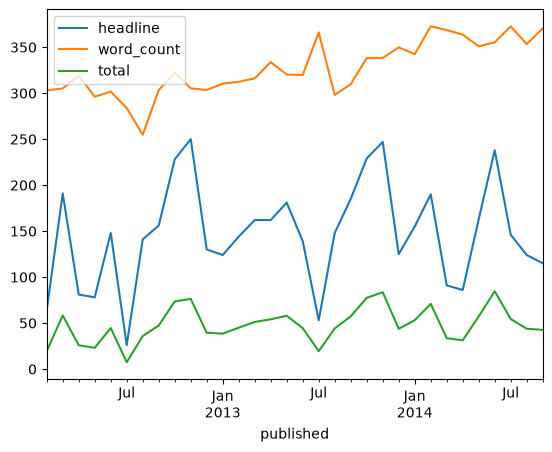

In [86]:
import matplotlib.pyplot as plt
df_g = df.groupby(pd.Grouper(key='published',freq='ME')).agg({'headline':'count','word_count':'mean'})
df_g['total'] = (df_g['headline'] * df_g['word_count'])/1000
df_g.plot()